# HBC Data

In [16]:
from STalign import STalign
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import plotly
import requests
import scanpy as sc
import matplotlib
import os

import warnings
warnings.filterwarnings("ignore")

## Load Data

In [17]:
# load Merfish mouse brain 33 data
file_path = './xenium_rep1_io_aligned.h5'
file_path2 = './xenium_rep2_io_aligned.h5'

ad = sc.read(file_path2)
ad_target = sc.read(file_path)

In [18]:
ad.obs['original_clusters'] = ad.obs['celltype_minor']
ad_target.obs['original_clusters'] = ad_target.obs['celltype_minor']

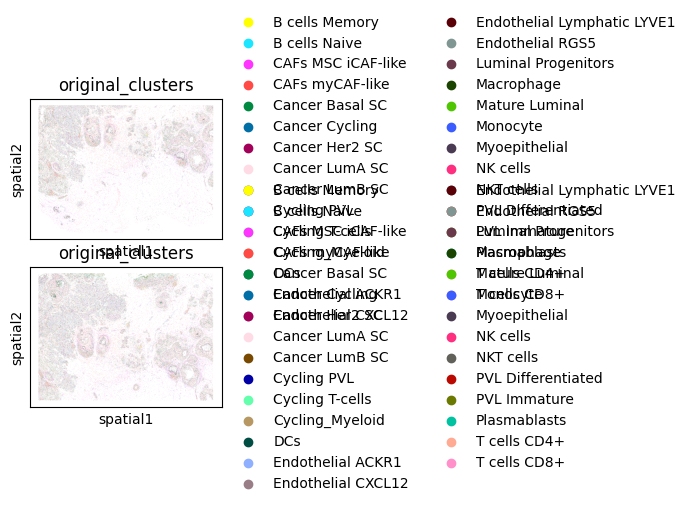

In [19]:
fig, axes = plt.subplots(2, 1, figsize=(6, 4))
sc.pl.spatial(ad, color='original_clusters', spot_size=5, ax=axes[0], show=False)
sc.pl.spatial(ad_target, color='original_clusters', spot_size=5, ax=axes[1], show=False)
plt.show()

Text(0.5, 1.0, 'Rasterized')

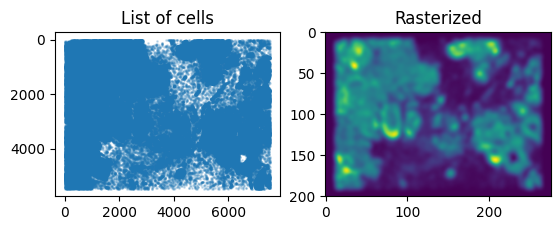

In [20]:
spatial_coords_target = ad_target.obsm['spatial']
x_target = spatial_coords_target[:, 0]
y_target = spatial_coords_target[:, 1]

#Rasterize Image
XJ,YJ,J = STalign.rasterize(x_target,y_target,dx=30,blur=1.5,draw=False)

#Plot unrasterized/rasterized images
fig,ax = plt.subplots(1,2)
ax[0].scatter(x_target,y_target,s=1,alpha=0.2)
ax[0].invert_yaxis()
ax[0].set_title('List of cells')
ax[0].set_aspect('equal')
 
# extent = (XI[0],XI[-1],YI[0],YI[-1])
ax[1].imshow(J[0],  origin='lower')
ax[1].invert_yaxis()
ax[1].set_title('Rasterized')

Text(0.5, 1.0, 'Rasterized')

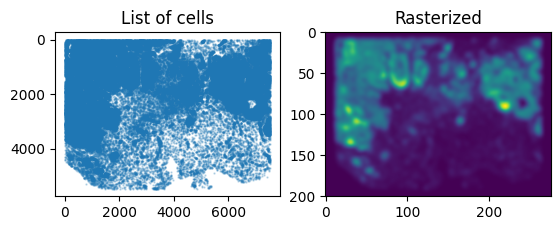

In [21]:
spatial_coords = ad.obsm['spatial']
x = spatial_coords[:, 0]
y = spatial_coords[:, 1]

#Rasterize Image
XI,YI,I = STalign.rasterize(x,y,dx=30,blur=1.5,draw=False)

#Plot unrasterized/rasterized images
fig,ax = plt.subplots(1,2)
ax[0].scatter(x,y,s=0.5,alpha=0.25)
ax[0].invert_yaxis()
ax[0].set_title('List of cells')
ax[0].set_aspect('equal')
 
# extent = (XI[0],XI[-1],YI[0],YI[-1])
ax[1].imshow(I[0],  origin='lower')
ax[1].invert_yaxis()
ax[1].set_title('Rasterized')

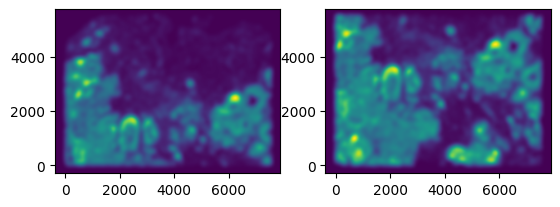

In [13]:
# get extent of images
extentI = STalign.extent_from_x((YI,XI))
extentJ = STalign.extent_from_x((YJ,XJ))

# plot rasterized images
fig,ax = plt.subplots(1,2)
ax[0].imshow(I[0], extent=extentI)
ax[1].imshow(J[0], extent=extentJ)
ax[0].invert_yaxis()
ax[1].invert_yaxis()

In [22]:
np.savez('./npz_data/rep1', x=XI,y=YI,I=I)
np.savez('./npz_data/rep2', x=XJ,y=YJ,I=J)

In [23]:
# read from file
pointsIlist = np.load('./npz_data/rep1_curves.npy', allow_pickle=True).tolist()
print(pointsIlist)
pointsJlist = np.load('./npz_data/rep2_curves.npy', allow_pickle=True).tolist()
print(pointsJlist)

{'0': [(6202.034404596474, 2440.826011254815)], '1': [(4566.06666266099, 2961.6647209322346)], '2': [(2409.2602110480875, 1599.471172545138)]}
{'0': [(5834.439637350883, 4376.9447883544135)], '1': [(4198.471895415398, 4931.170594806026)], '2': [(2101.7622179960435, 3462.13833674151)]}


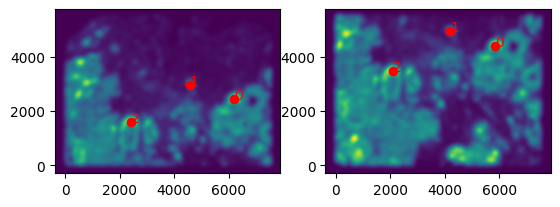

In [24]:
# convert to array
pointsI = []
pointsJ = []

# Jean's note: a bit odd to me that the points are stored as y,x
## instead of x,y but all downstream code uses this orientation
for i in pointsIlist.keys():
    pointsI.append([pointsIlist[i][0][1], pointsIlist[i][0][0]])
for i in pointsJlist.keys():
    pointsJ.append([pointsJlist[i][0][1], pointsJlist[i][0][0]])

pointsI = np.array(pointsI)
pointsJ = np.array(pointsJ)

# get extent of images
extentI = STalign.extent_from_x((YI,XI))
extentJ = STalign.extent_from_x((YJ,XJ))

# plot rasterized images
fig,ax = plt.subplots(1,2)
ax[0].imshow((I.transpose(1,2,0).squeeze()), extent=extentI) # just want 201x276 matrix
ax[1].imshow((J.transpose(1,2,0).squeeze()), extent=extentJ) # just want 201x276 matrix
# with points
ax[0].scatter(pointsI[:,1], pointsI[:,0], c='red')
ax[1].scatter(pointsJ[:,1], pointsJ[:,0], c='red')
for i in range(pointsI.shape[0]):
    ax[0].text(pointsI[i,1],pointsI[i,0],f'{i}', c='red')
    ax[1].text(pointsJ[i,1],pointsJ[i,0],f'{i}', c='red')
ax[0].invert_yaxis()
ax[1].invert_yaxis()

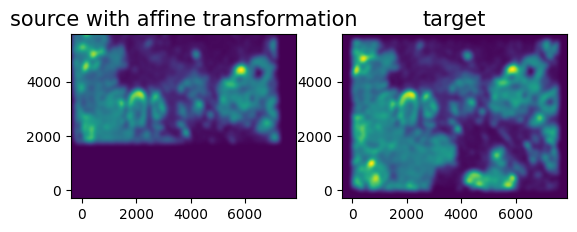

In [25]:
# set device for building tensors
if torch.cuda.is_available():
    torch.set_default_device('cuda:0')
else:
    torch.set_default_device('cpu')

# compute initial affine transformation from points
L,T = STalign.L_T_from_points(pointsI, pointsJ)
A = STalign.to_A(torch.tensor(L),torch.tensor(T))

# compute initial affine transformation from points
AI = STalign.transform_image_source_with_A(A, [YI,XI], I, [YJ,XJ])

#switch tensor from cuda to cpu for plotting with numpy
if AI.is_cuda:
    AI = AI.cpu()

fig,ax = plt.subplots(1,2)
ax[0].imshow((AI.permute(1,2,0).squeeze()), extent=extentJ)
ax[1].imshow((J.transpose(1,2,0).squeeze()), extent=extentJ)

ax[0].set_title('source with affine transformation', fontsize=15)
ax[1].set_title('target', fontsize=15)

ax[0].invert_yaxis()
ax[1].invert_yaxis()

CPU times: total: 2min 38s
Wall time: 36.3 s


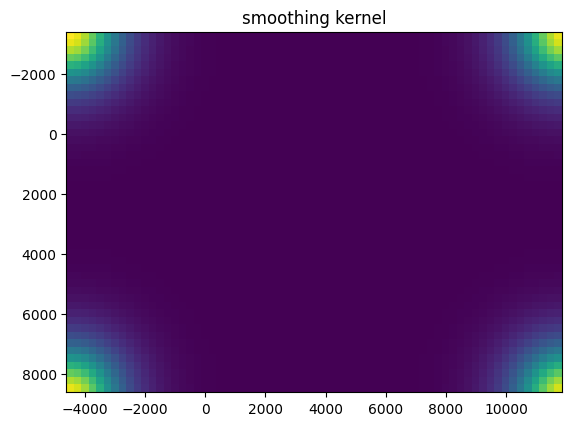

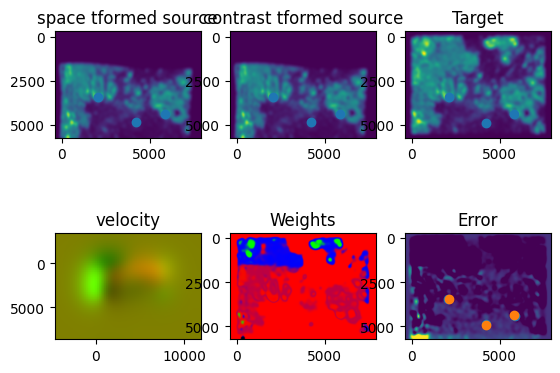

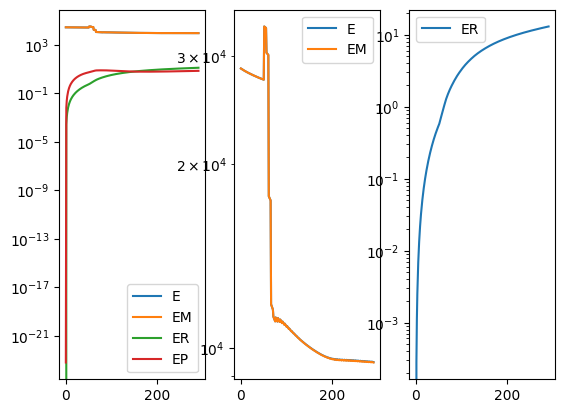

In [51]:
%%time
# run LDDMM
# specify device (default device for STalign.LDDMM is cpu)
if torch.cuda.is_available():
    device = 'cuda:0'
else:
    device = 'cpu'
    
muB = torch.tensor([0,0,0])
muB = muB.to(device)
J = torch.tensor(J, device=muB.device, dtype=torch.float32)

# keep all other parameters default
params = {
    'L':L,'T':T,
    'niter':300,
    'pointsI':pointsI,
    'pointsJ':pointsJ,
    'device':device,
    'sigmaM':1.5,
    'sigmaB':1.0,
    'sigmaA':1.1,
    'epV': 100
}

out = STalign.LDDMM([YI,XI],I,[YJ,XJ],J,**params)

In [52]:
# get necessary output variables
A = out['A']
v = out['v']
xv = out['xv']

In [53]:
pointsI = torch.tensor(np.stack([y, x], 1), device='cuda', dtype=torch.float64)

# apply transform to original points
tpointsI= STalign.transform_points_source_to_target(xv,v,A, pointsI)

#switch tensor from cuda to cpu for plotting with numpy
if tpointsI.is_cuda:
    tpointsI = tpointsI.cpu()

#switch from row column coordinates (y,x) to (x,y)
xI_LDDMM = tpointsI[:,1]
yI_LDDMM = tpointsI[:,0]

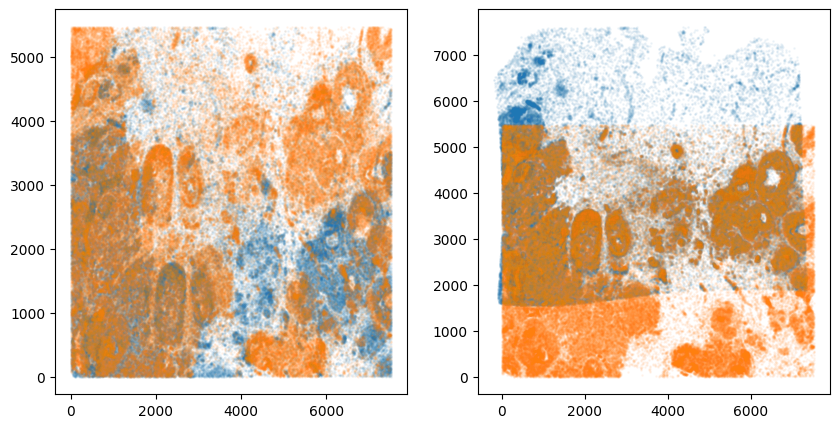

In [54]:
fig,ax = plt.subplots(1,2, figsize=(10, 5))
ax[0].scatter(x,y,s=1,alpha=0.05, label='source with initial affine transformation')
ax[0].scatter(x_target,y_target,s=1,alpha=0.05, label='target')
ax[1].scatter(xI_LDDMM,yI_LDDMM,s=1,alpha=0.05, label = 'source STaligned')
ax[1].scatter(x_target,y_target,s=1,alpha=0.05, label='target')
# ax[0].legend(markerscale = 10, loc = 'lower left')
# ax[1].legend(markerscale = 10, loc = 'lower left')

## LAA & ARI

In [55]:
from scipy.spatial import cKDTree
from sklearn.metrics import adjusted_rand_score


def find_nearest_points(f1, f2):
    """
    Find the nearest point in f2 for each point in f1 using batch processing.
    
    Args:
        f1 (numpy.ndarray): Array of shape (n_points_1, 2) representing points in f1.
        f2 (numpy.ndarray): Array of shape (n_points_2, 2) representing points in f2.
        batch_size (int): Number of points to process in each batch.
        
    """
    # Build a k-d tree for f2
    tree = cKDTree(f2)
    
    # Query the k-d tree for nearest neighbors of points in f1
    distances, nearest_indices = tree.query(f1)
        
    cnt = 0
    true_clusters_mapped_region = []
    mapped_clusters_mapped_region = []

    for i in range(len(f1)):
        f1_cluster = ad_target.obs.iloc[i]['original_clusters']
        f2_cluster = ad.obs.iloc[nearest_indices[i]]['original_clusters']
        true_clusters_mapped_region.append(f1_cluster)
        mapped_clusters_mapped_region.append(f2_cluster)
        if f1_cluster == f2_cluster:
            cnt += 1 

    laa = cnt/len(f2)
    ari = adjusted_rand_score(true_clusters_mapped_region, mapped_clusters_mapped_region)
              
    return laa,ari


In [56]:
f1 = np.column_stack((x_target, y_target))  # Shape: (n_points, 2)
f2 = np.column_stack((xI_LDDMM, yI_LDDMM))  # Shape: (n_points, 2)

laa,ari = find_nearest_points(f1, f2)

print(laa)
print(ari)

0.16366040150902722
0.023168576067213835


## 3D

In [57]:
dfs = ad_target.obs['original_clusters']
df1 = dfs.reset_index()
df1.head()

,index,original_clusters
0,0,Myoepithelial
1,1,Cancer LumA SC
2,2,Endothelial RGS5
3,3,Plasmablasts
4,4,Cancer LumA SC


In [58]:
df3_1 = pd.DataFrame(
    {
        "X": x_target,
        "Y": y_target,
    },
)

results1 = pd.concat([df1, df3_1], axis=1)
results1['Z'] = 1
results1['slice'] = 'rep2'
results1

,index,original_clusters,X,Y,Z,slice
0,0,Myoepithelial,847.259912,326.191365,1,rep2
1,1,Cancer LumA SC,826.341995,328.031830,1,rep2
2,2,Endothelial RGS5,848.766919,331.743187,1,rep2
3,3,Plasmablasts,824.228409,334.252643,1,rep2
4,4,Cancer LumA SC,841.357538,332.242505,1,rep2
...,...,...,...,...,...,...
167775,167775,Cancer LumA SC,7455.475342,5114.875415,1,rep2
167776,167776,Cancer Her2 SC,7483.727051,5111.477490,1,rep2
167777,167777,Cancer Her2 SC,7470.159424,5119.132056,1,rep2
167778,167778,Cancer LumB SC,7477.737207,5128.712817,1,rep2


In [59]:
results1.to_csv("2.csv", index=False)

In [60]:
dfs = ad.obs['original_clusters']
df1 = dfs.reset_index()
df1.head()

,index,original_clusters
0,0,Cycling T-cells
1,1,CAFs myCAF-like
2,2,Cycling T-cells
3,3,DCs
4,4,Cycling T-cells


In [61]:
df3_1 = pd.DataFrame(
    {
        "X": xI_LDDMM,
        "Y": yI_LDDMM,
    },
)

results1 = pd.concat([df1, df3_1], axis=1)
results1['Z'] = 0
results1['slice'] = 'rep1'
results1

,index,original_clusters,X,Y,Z,slice
0,0,Cycling T-cells,379.031605,2551.422670,0,rep1
1,1,CAFs myCAF-like,379.075469,2530.616108,0,rep1
2,2,Cycling T-cells,387.268768,2535.173638,0,rep1
3,3,DCs,388.363706,2547.827997,0,rep1
4,4,Cycling T-cells,388.345974,2519.849671,0,rep1
...,...,...,...,...,...,...
118747,118747,PVL Immature,7106.294274,6363.550225,0,rep1
118748,118748,Endothelial ACKR1,7088.860553,6370.231522,0,rep1
118749,118749,Endothelial ACKR1,7115.382102,6376.754715,0,rep1
118750,118750,Endothelial ACKR1,7099.054579,6384.336878,0,rep1


In [62]:
results1.to_csv("1.csv", index=False)